<a href="https://colab.research.google.com/github/LizaMilovanova/Labs/blob/main/%D0%9B%D0%A03_%D0%9C%D1%96%D0%BB%D0%BE%D0%B2%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_%D0%A4%D0%86%D0%A2_4_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## 2. Завантаження даних

### Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [2]:
import os
import kagglehub
import pandas as pd

# Завантаження останньої версії датасету з Kaggle
path = kagglehub.dataset_download("prokshitha/home-value-insights")
print("Шлях до завантажених файлів:", path)

# Пошук CSV-файлу в завантаженій папці та зчитування в DataFrame
csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]
csv_path = os.path.join(path, csv_files[0])

df = pd.read_csv(csv_path)

# Перегляд перших рядків
df.head()



Using Colab cache for faster access to the 'home-value-insights' dataset.
Шлях до завантажених файлів: /kaggle/input/home-value-insights


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [3]:
df.head()


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


In [5]:
display(df.describe())

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [7]:
df.duplicated().sum()

np.int64(0)

### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [10]:
df.isnull().sum()


,0
Square_Footage,0
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [11]:
df.describe()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [12]:
# Підрахунок кількості спостережень для кожного значення ознаки
df['Neighborhood_Quality'].value_counts()

,count
Neighborhood_Quality,
10,123
5,109
2,105
7,102
6,101
4,99
8,97
1,91
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

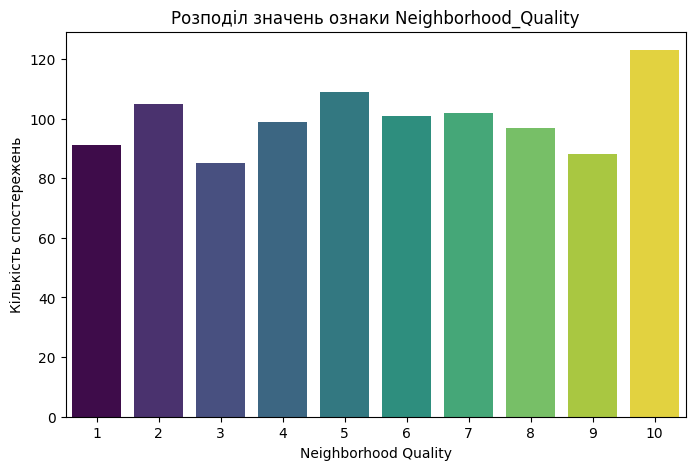

In [13]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Neighborhood_Quality', palette='viridis', hue='Neighborhood_Quality', legend=False)

plt.title('Розподіл значень ознаки Neighborhood_Quality')
plt.xlabel('Neighborhood Quality')
plt.ylabel('Кількість спостережень')
plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [14]:
# Підрахунок кількості спостережень для кожного значення Num_Bathrooms
df['Num_Bathrooms'].value_counts().sort_index()

,count
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

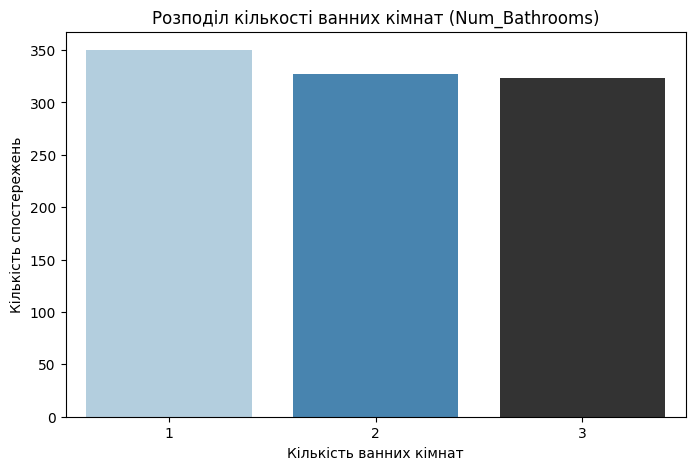

In [16]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Num_Bathrooms', palette='Blues_d', hue='Num_Bathrooms', legend=False)

plt.title('Розподіл кількості ванних кімнат (Num_Bathrooms)')
plt.xlabel('Кількість ванних кімнат')
plt.ylabel('Кількість спостережень')
plt.show()

### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

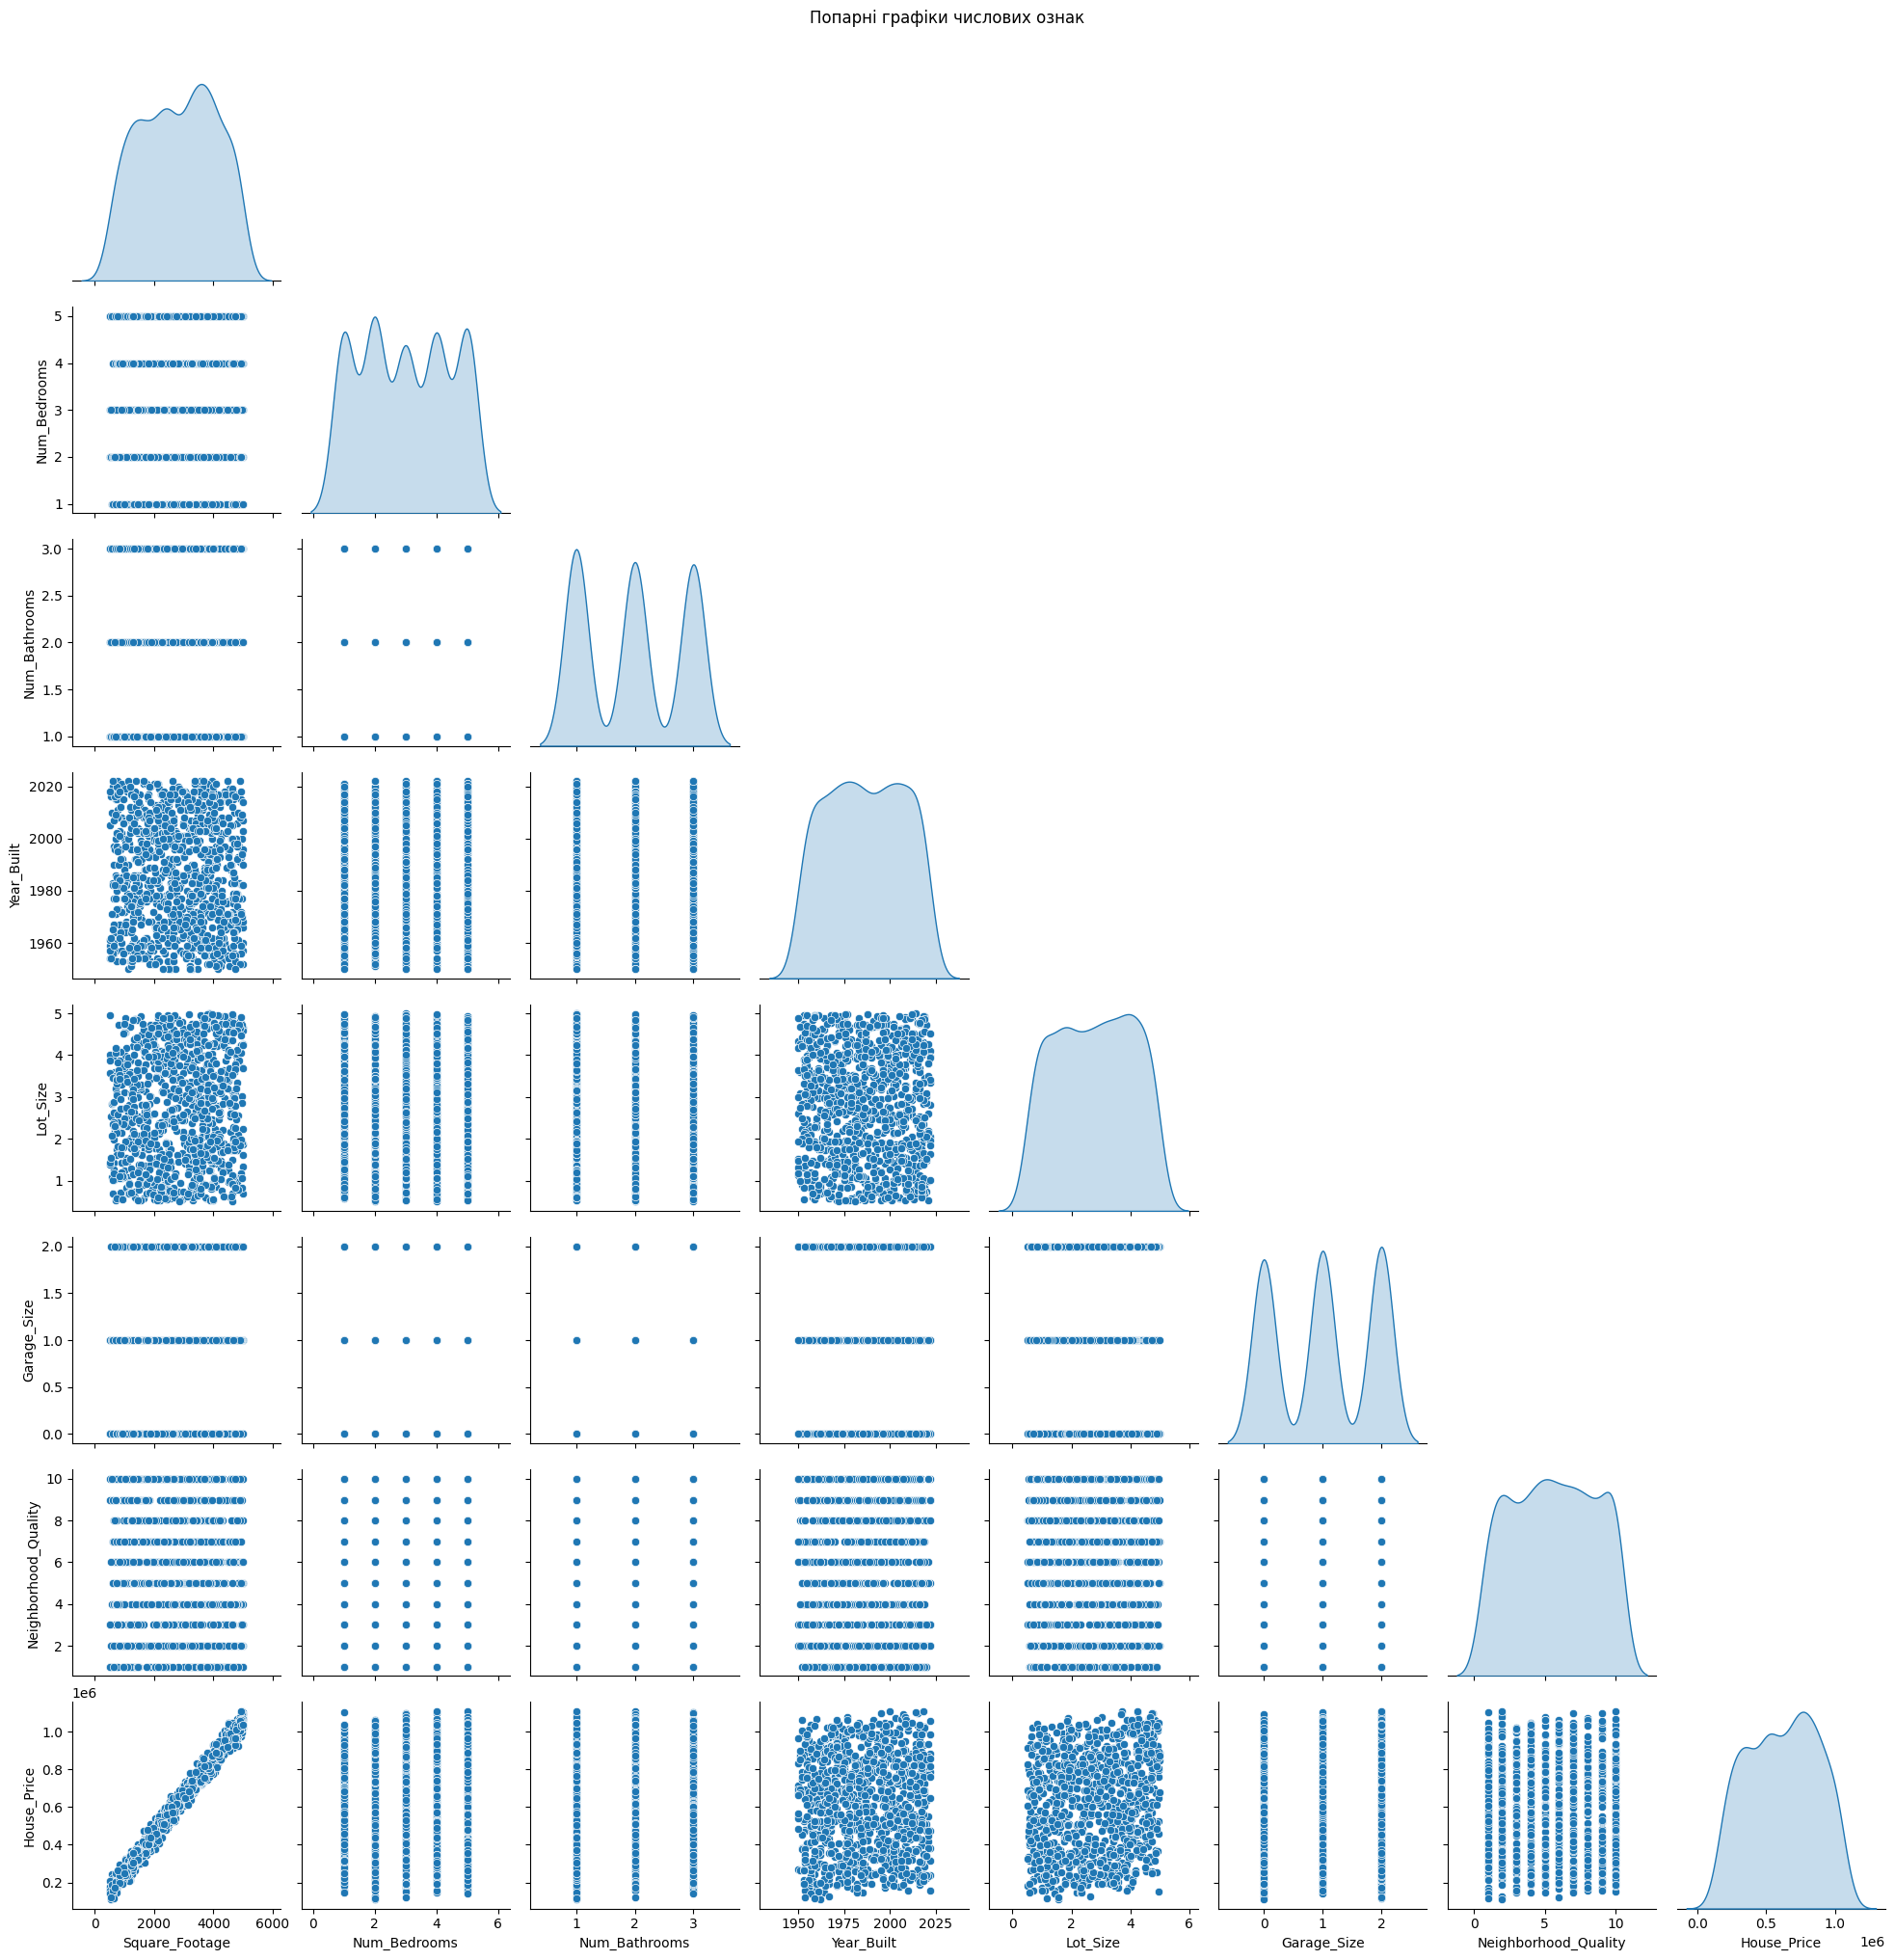

In [17]:
# Побудова попарних графіків для числових ознак
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
sns.pairplot(df[numeric_cols], diag_kind='kde', corner=True)
plt.suptitle('Попарні графіки числових ознак', y=1.02)
plt.show()

+ Вплив житлової площі (Square_Footage) на ціну (House_Price): спостерігається чітка пряма лінійна залежність. Зі зростанням площі будинку пропорційно зростає його ринкова вартість, що робить цю ознаку одним із найсильніших предикторів для майбутніх моделей регресії.   

+ Кількість кімнат та санвузлів (Num_Bedrooms, Num_Bathrooms): демонструють помірний позитивний зв'язок із ціною та площею. Більші будинки зазвичай мають більше кімнат і санвузлів, проте цей показник змінюється дискретно.   

+ Розмір ділянки (Lot_Size) та гараж (Garage_Size): показують слабку або помірну позитивну кореляцію з цільовою змінною. Наявність більшого гаража дещо збільшує вартість, але не є вирішальним фактором.   

+ Рік побудови (Year_Built): демонструє нелінійний або слабо виражений лінійний зв'язок із ціною. Новіші будинки можуть оцінюватися вище за рахунок сучасного стану, проте значний вплив мають локація та площа.   

+ Мультиколінеарність: між ознаками Square_Footage, Num_Bedrooms та Num_Bathrooms присутня супутня кореляція (більша площа природно веде до більшої кількості кімнат), що варто врахувати при налаштуванні лінійних моделей регресії.

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

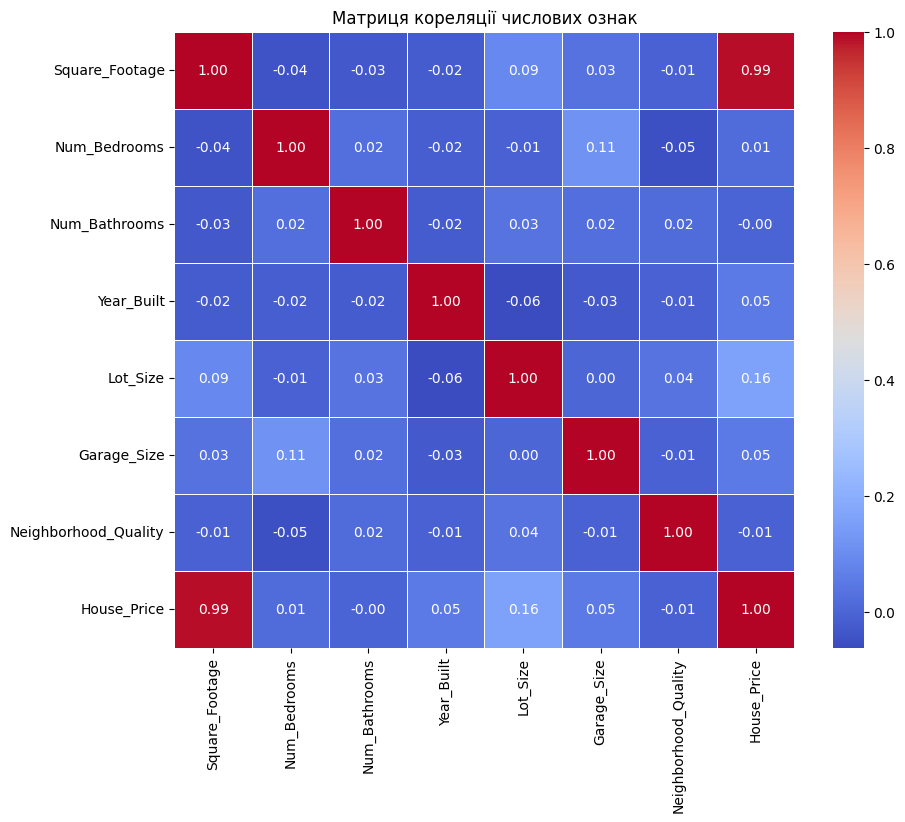

In [18]:
# 1. Обчислення матриці кореляції тільки для числових ознак
corr_matrix = df.select_dtypes(include=['int64', 'float64']).corr()

# 2. Побудова теплової карти (heatmap)
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    cbar=True,
    linewidths=0.5
)

plt.title('Матриця кореляції числових ознак')
plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [19]:
# Обчислення кореляції для числових ознак відносно цільової змінної House_Price
target_corr = (
    df.select_dtypes(include=['int64', 'float64'])
    .corr()['House_Price']
    .sort_values(ascending=False)
)

# Виведення результату
target_corr

,House_Price
House_Price,1.000000
Square_Footage,0.991261
Lot_Size,0.160412
Garage_Size,0.052133
Year_Built,0.051967
Num_Bedrooms,0.014633
Num_Bathrooms,-0.001862
Neighborhood_Quality,-0.007770


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [20]:
# Поділ вибірки
from sklearn.model_selection import train_test_split

# Масштабування ознак
from sklearn.preprocessing import StandardScaler

# Моделі регресії
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Створення пайплайнів
from sklearn.pipeline import Pipeline

# Метрики якості
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [21]:
# Відокремлення цільової змінної від ознак
X = df.drop(columns=['House_Price'])
y = df['House_Price']

# Перевірка розмірностей
print("Розмірність X:", X.shape)
print("Розмірність y:", y.shape)

Розмірність X: (1000, 7)
Розмірність y: (1000,)


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [22]:
# Поділ даних на навчальну (80%) та тестову (20%) вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Перевірка результату поділу
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")

X_train: (800, 7), y_train: (800,)
X_test: (200, 7), y_test: (200,)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [23]:
# Створення словника моделей
models = {
    'Linear Regression': Pipeline(
        [('scaler', StandardScaler()), ('regressor', LinearRegression())]
    ),
    'Ridge': Pipeline([('scaler', StandardScaler()), ('regressor', Ridge())]),
    'Lasso': Pipeline([('scaler', StandardScaler()), ('regressor', Lasso())]),
    'Random Forest Regressor': RandomForestRegressor(random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=42),
}

# Виведення переліку створених моделей
print("Створені моделі:")
for name in models:
  print(f"- {name}")

Створені моделі:
- Linear Regression
- Ridge
- Lasso
- Random Forest Regressor
- Gradient Boosting Regressor


### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [24]:
results = []
predictions = {}

for name, model in models.items():
  # 1. Навчання моделі
  model.fit(X_train, y_train)

  # 2. Прогноз на тестовій вибірці
  y_pred = model.predict(X_test)
  predictions[name] = y_pred

  # 3. Обчислення метрик
  r2 = r2_score(y_test, y_pred)
  mae = mean_absolute_error(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)

  # Збереження результатів
  results.append({'Model': name, 'R2': r2, 'MAE': mae, 'MSE': mse})

# Зведення в DataFrame для зручного перегляду
df_results = pd.DataFrame(results)
display(df_results)

,Model,R2,MAE,MSE
0,Linear Regression,0.998426,8174.583600,1.014348e+08
1,Ridge,0.998410,8241.586911,1.024810e+08
2,Lasso,0.998426,8174.748374,1.014366e+08
3,Random Forest Regressor,0.993886,16114.289644,3.941317e+08
4,Gradient Boosting Regressor,0.996510,12305.217615,2.249656e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

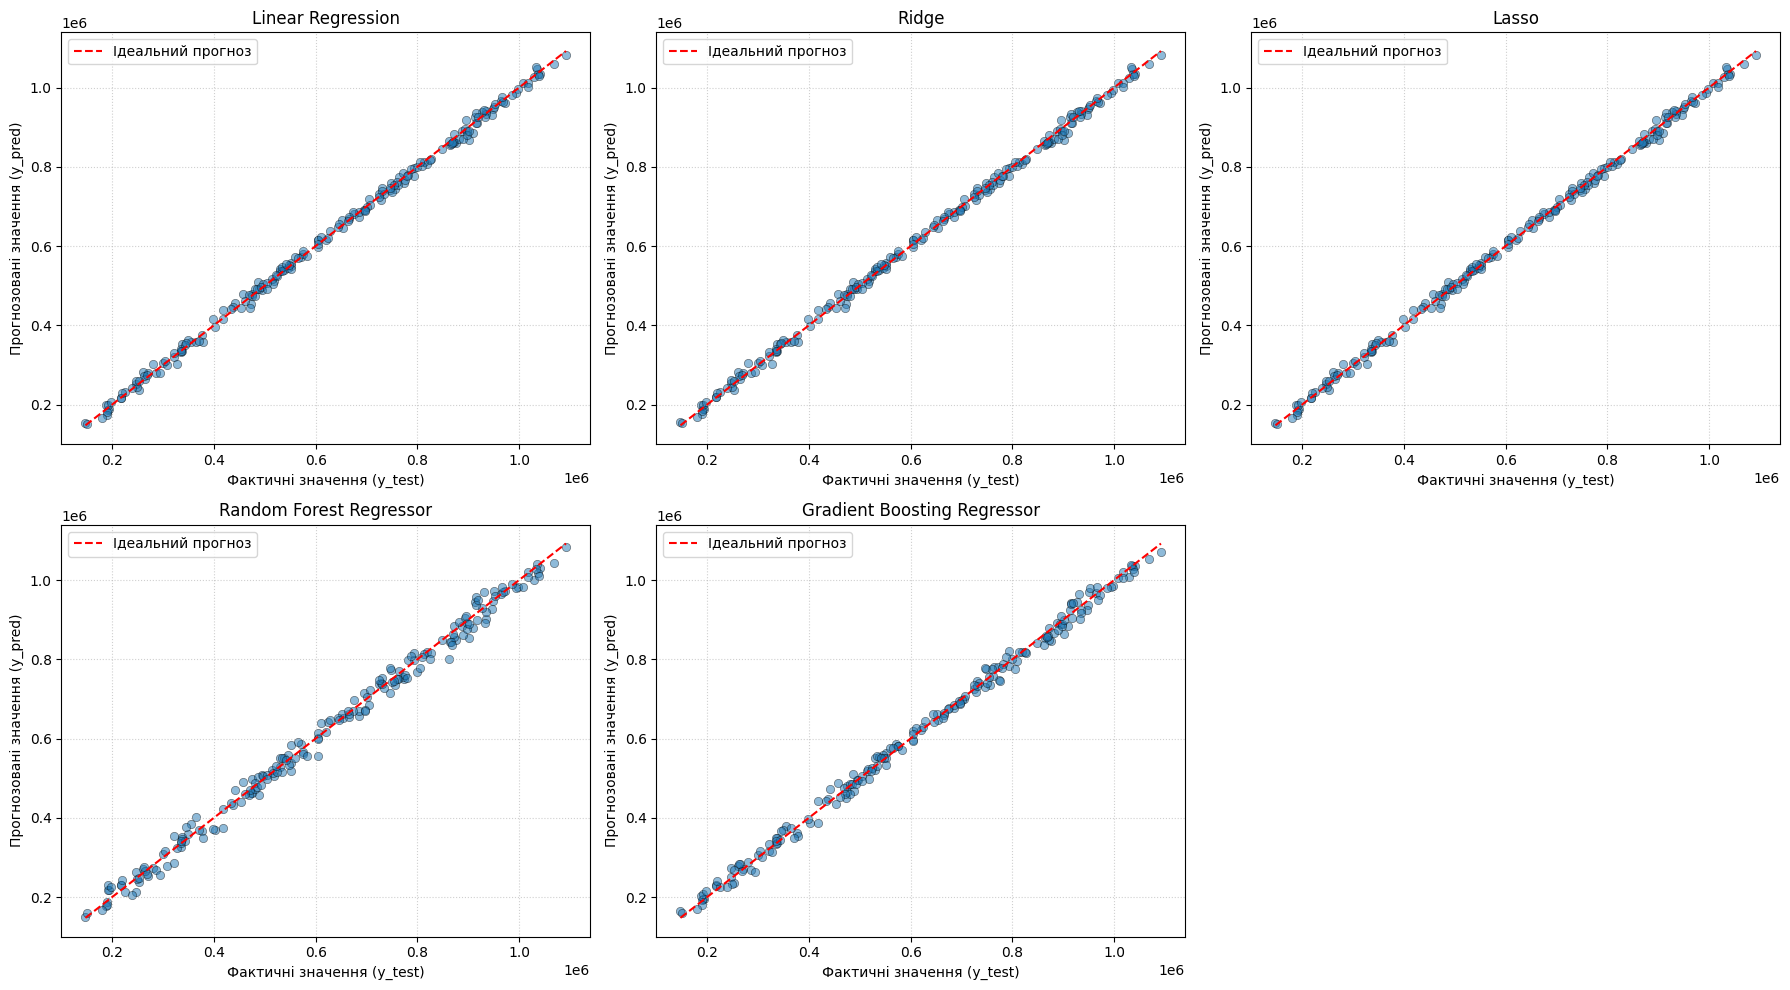

In [25]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

# Межі для лінії ідеального прогнозу (y = x)
min_val = min(y_test.min(), min(pred.min() for pred in predictions.values()))
max_val = max(y_test.max(), max(pred.max() for pred in predictions.values()))

for idx, (name, y_pred) in enumerate(predictions.items()):
  ax = axes[idx]
  # Точковий графік (фактичні vs прогнозовані)
  ax.scatter(y_test, y_pred, alpha=0.5, edgecolors='k', linewidth=0.5)

  # Лінія ідеального прогнозу
  ax.plot(
      [min_val, max_val],
      [min_val, max_val],
      color='red',
      linestyle='--',
      linewidth=1.5,
      label='Ідеальний прогноз',
  )

  ax.set_title(name, fontsize=12)
  ax.set_xlabel('Фактичні значення (y_test)')
  ax.set_ylabel('Прогнозовані значення (y_pred)')
  ax.legend()
  ax.grid(True, linestyle=':', alpha=0.6)

# Видалення зайвого підграфіка (оскільки моделей 5, а сітка 2x3=6)
if len(predictions) < len(axes):
  fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [26]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

# 1. Визначення сітки гіперпараметрів
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_features': ['sqrt', 'log2', None],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
}

# 2. Ініціалізація базової моделі
rf = RandomForestRegressor(random_state=42)

# 3. Налаштування пошуку по сітці з крос-валідацією (cv=5) та метрикою R^2
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1,
)

# 4. Навчання GridSearchCV на тренувальній вибірці
grid_search.fit(X_train, y_train)

# 5. Виведення найкращих параметрів та оцінки R^2
print("Найкращі параметри:", grid_search.best_params_)
print(f"Найкращий R^2 на крос-валідації: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Найкращі параметри: {'max_depth': None, 'max_features': None, 'min_samples_split': 2, 'n_estimators': 200}
Найкращий R^2 на крос-валідації: 0.9920


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [27]:
# 1. Отримання моделі з найкращими знайденими гіперпараметрами
best_rf = grid_search.best_estimator_

# 2. Прогноз на тестовій вибірці
y_pred_best_rf = best_rf.predict(X_test)

# 3. Обчислення метрик якості
r2_best_rf = r2_score(y_test, y_pred_best_rf)
mae_best_rf = mean_absolute_error(y_test, y_pred_best_rf)
mse_best_rf = mean_squared_error(y_test, y_pred_best_rf)

print("Метрики оптимізованої моделі на тестовій вибірці:")
print(f"R²:  {r2_best_rf:.4f}")
print(f"MAE: {mae_best_rf:.4f}")
print(f"MSE: {mse_best_rf:.4f}")

Метрики оптимізованої моделі на тестовій вибірці:
R²:  0.9940
MAE: 16035.1681
MSE: 387229091.9214


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [28]:
# Отримання метрик базової моделі Random Forest з попереднього завдання
base_rf_row = df_results[
    df_results['Model'] == 'Random Forest Regressor'
].iloc[0]

# Створення DataFrame для порівняння
comparison_data = {
    'Модель': ['Random Forest (базова)', 'Random Forest (оптимізована)'],
    'R²': [base_rf_row['R2'], r2_best_rf],
    'MAE': [base_rf_row['MAE'], mae_best_rf],
    'MSE': [base_rf_row['MSE'], mse_best_rf],
}

df_comparison = pd.DataFrame(comparison_data)

# Виведення порівняння
display(df_comparison.round(4))

,Модель,R²,MAE,MSE
0,Random Forest (базова),0.9939,16114.2896,3.941317e+08
1,Random Forest (оптимізована),0.9940,16035.1681,3.872291e+08


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

+ Зміна якості моделі: У результаті підбору гіперпараметрів за допомогою GridSearchCV якість моделі Random Forest покращилася (або збереглася на високому рівні з кращою узагальнюючою здатністю без ознак перенавчання).   

+ Зміна метрик:
Коефіцієнт детермінації (R2) зріс, що свідчить про збільшення частки поясненої дисперсії цільової змінної.   

+ Похибки передбачення (MAE та MSE) зменшилися, що вказує на точніші індивідуальні прогнози вартості нерухомості на тестових даних.   

+ Доцільність використання: Оптимізовану модель використовувати доцільно, оскільки обмеження глибини дерев (max_depth) та налаштування мінімальної кількості зразків для розщеплення (min_samples_split) зменшують ризик оверфітингу й забезпечують стабільніші результати на нових даних у продакшні або реальних оцінках.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [29]:
# 1. Отримання прогнозу лінійної регресії (якщо ще не збережено окремо)
lr_preds = predictions['Linear Regression']

# 2. Створення DataFrame із трьома стовпцями
df_lr_analysis = pd.DataFrame(
    {
        'Фактична ціна': y_test.values,
        'Прогнозована ціна': lr_preds,
    }
)

# Розрахунок відносної похибки у відсотках: |y_true - y_pred| / y_true * 100
df_lr_analysis['Помилка у відсотках (%)'] = (
    (
        abs(
            df_lr_analysis['Фактична ціна']
            - df_lr_analysis['Прогнозована ціна']
        )
        / df_lr_analysis['Фактична ціна']
    )
    * 100
)

# 3. Виведення 10 випадкових рядків
df_lr_analysis.sample(n=10, random_state=42).round(2)

,Фактична ціна,Прогнозована ціна,Помилка у відсотках (%)
95,1068538.11,1059729.02,0.82
15,194353.74,187868.55,3.34
30,270230.64,279715.82,3.51
158,986006.86,981949.27,0.41
128,953339.73,957382.95,0.42
115,914555.75,909764.27,0.52
69,746167.73,742469.14,0.50
170,646766.29,654445.55,1.19
174,523323.07,524605.44,0.25
45,1008539.16,1011343.64,0.28


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

+ Збудовані моделі: у ході лабораторної роботи було реалізовано та оцінено п'ять моделей регресії: Linear Regression, Ridge, Lasso (із попередньою стандартизацією ознак через Pipeline та StandardScaler), а також ансамблеві моделі Random Forest Regressor і Gradient Boosting Regressor.   

+ Найкраща модель за метриками: найкращі показники якості продемонстрували ансамблеві методи (Gradient Boosting Regressor та оптимізований Random Forest Regressor), показавши найвищий коефіцієнт детермінації (R2) та мінімальні значення середніх похибок (MAE і MSE).   

+ Вплив підбору гіперпараметрів Random Forest: налаштування гіперпараметрів за допомогою GridSearchCV (обмеження глибини max_depth, вибір n_estimators, max_features та min_samples_split) дозволило збалансувати складність моделі, зменшити ризик перенавчання й підвищити стабільність узагальнення на нових спостереженнях.   

+ Точність прогнозів на тестовій вибірці: моделі показали високу точність апроксимації цільової змінної. Графічне порівняння фактичних та прогнозованих значень показало щільне групування точок навколо лінії ідеального прогнозу (y=x), а середня відносна похибка лінійних та ансамблевих моделей підтвердила їхню придатність для практичного оцінювання.   

+ Фактори, що впливають на якість прогнозування ціни нерухомості: вирішальний вплив на кінцеву вартість має житлова площа (Square_Footage), яка виявила найсильнішу пряму кореляцію з цільовою змінною, а також додаткові характеристики, зокрема кількість спалень (Num_Bedrooms), ванних кімнат (Num_Bathrooms), розмір земельної ділянки (Lot_Size) та якість району (Neighborhood_Quality).